# Peak-week results analysis

This notebook uses the repository-wide analysis schema. All calculations, validation, plotting, and exports come from `scripts/results_analysis`; this notebook only selects a run and presents the results. The default result is written by `9BA_run_peakday_2025_26.ipynb`. For a named peak run from `9BA_run_model.ipynb`, set `RESULT_PATH` to its `results/run_results/peak_YYYY-MM-DD/<run_name>/` folder.

In [1]:
# ===================== USER SETTINGS =====================
RESULT_PATH = 'results/tamil_nadu_9ba_2025_26.nc'
OUTPUT_DIR = None  # None writes to results/analysis for this .nc file
SAVE_TABLES_AND_FIGURES = True
# =========================================================

## Load the solved run

Cannot find header.dxf (GDAL_DATA is not defined)
c:\Users\b076218\AppData\Local\anaconda3\envs\pypsa\Lib\site-packages\xarray\backends\plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
INFO:pypsa.io:Imported network tamil_nadu_9ba_2025_26.nc has buses, carriers, generators, global_constraints, links, loads, storage_units


Loaded single_network: 2025-07-07 00:00:00 to 2025-07-13 23:00:00 (168 hours)


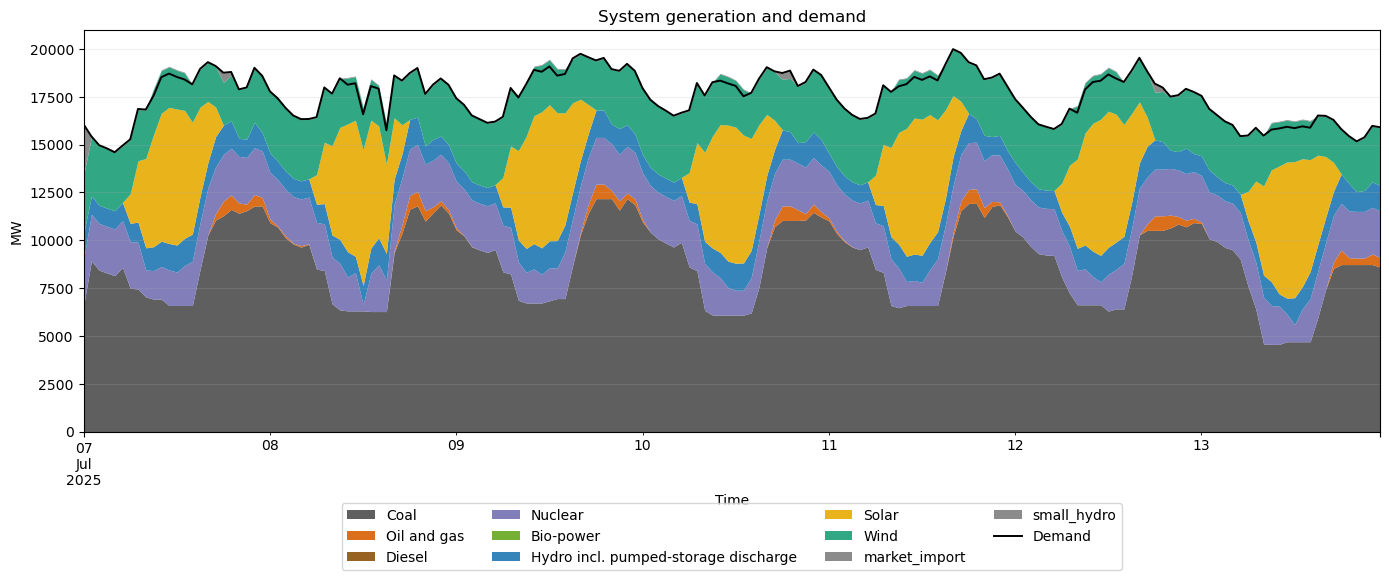

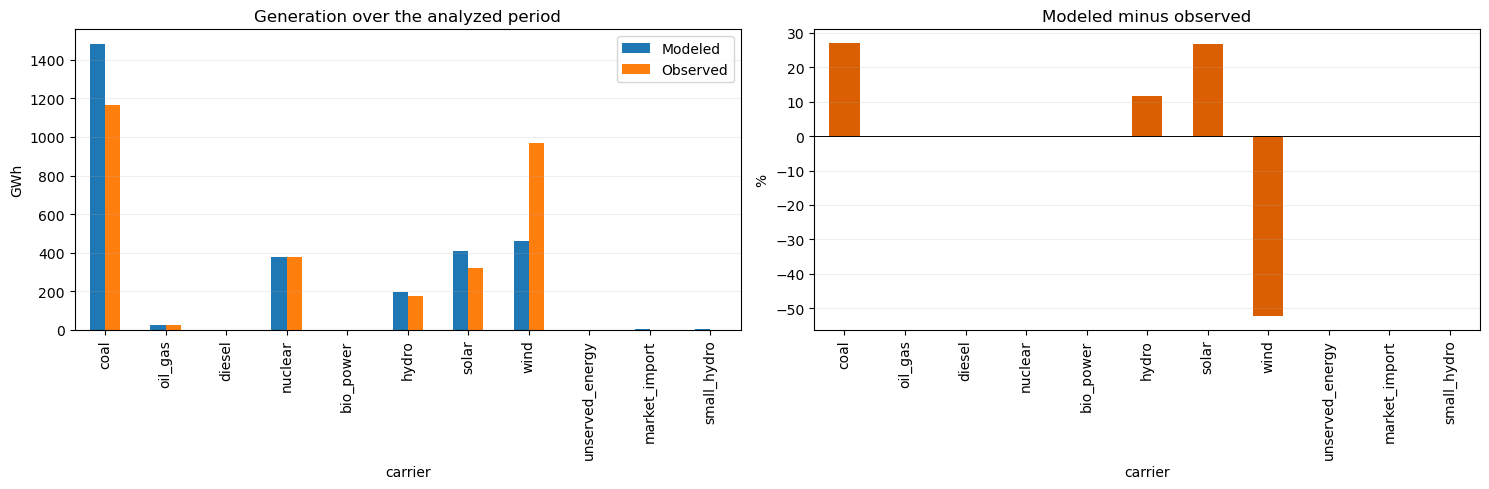

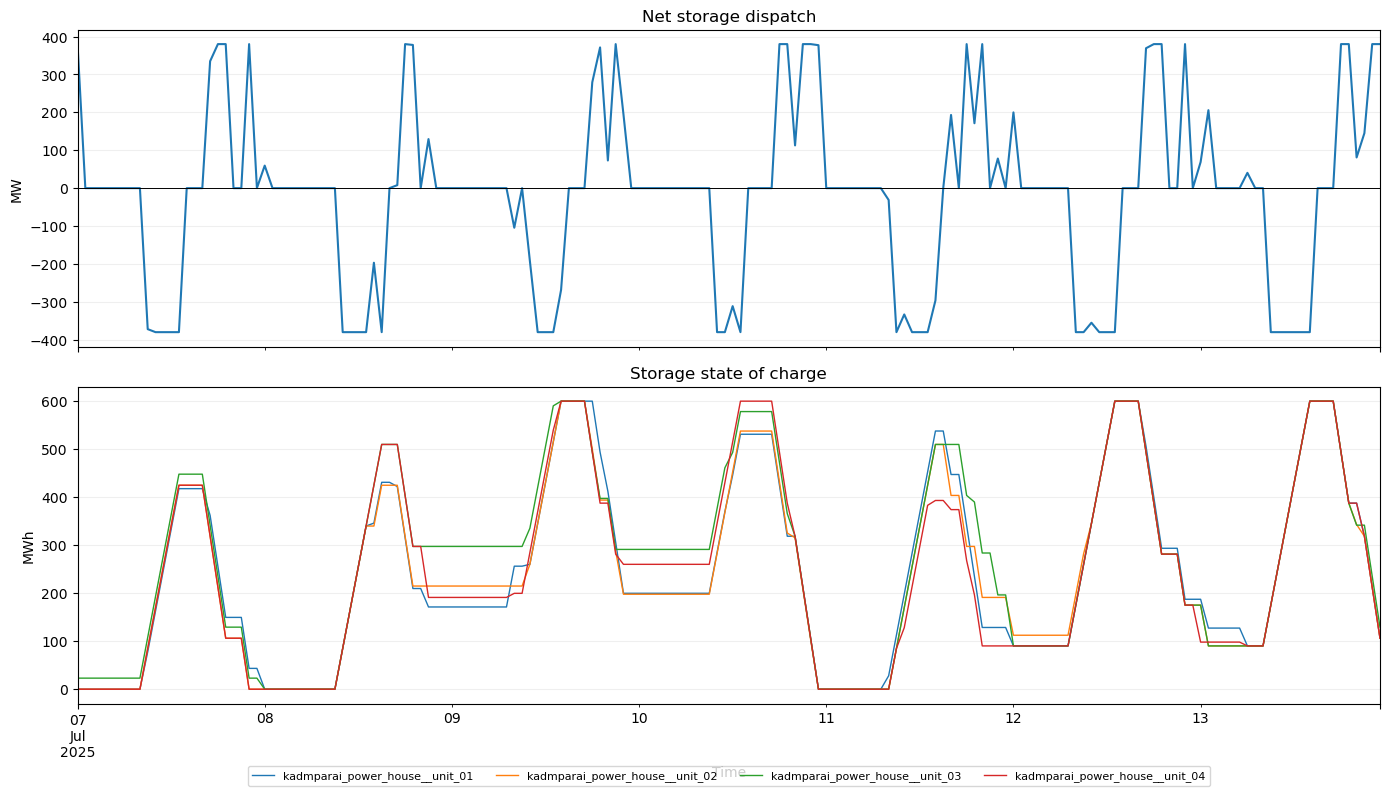

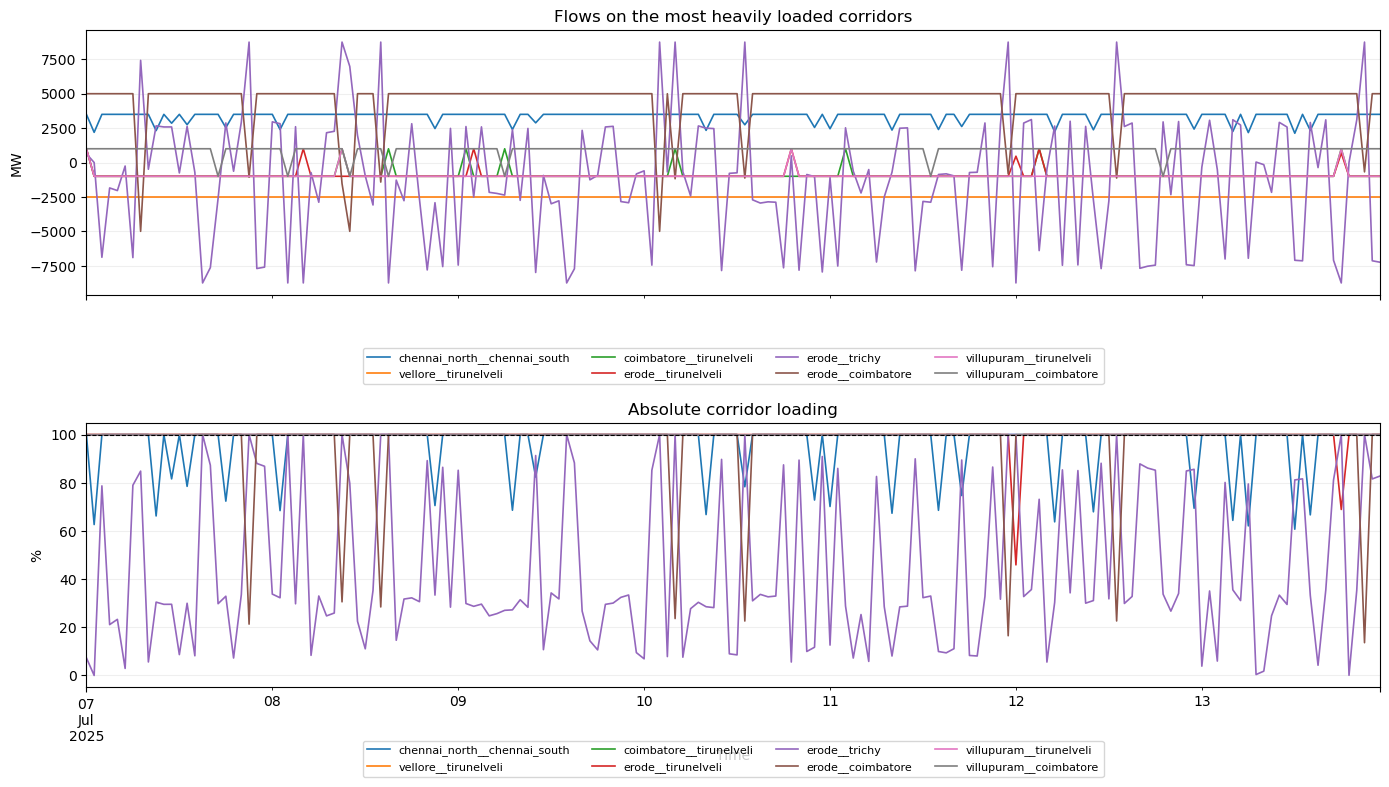

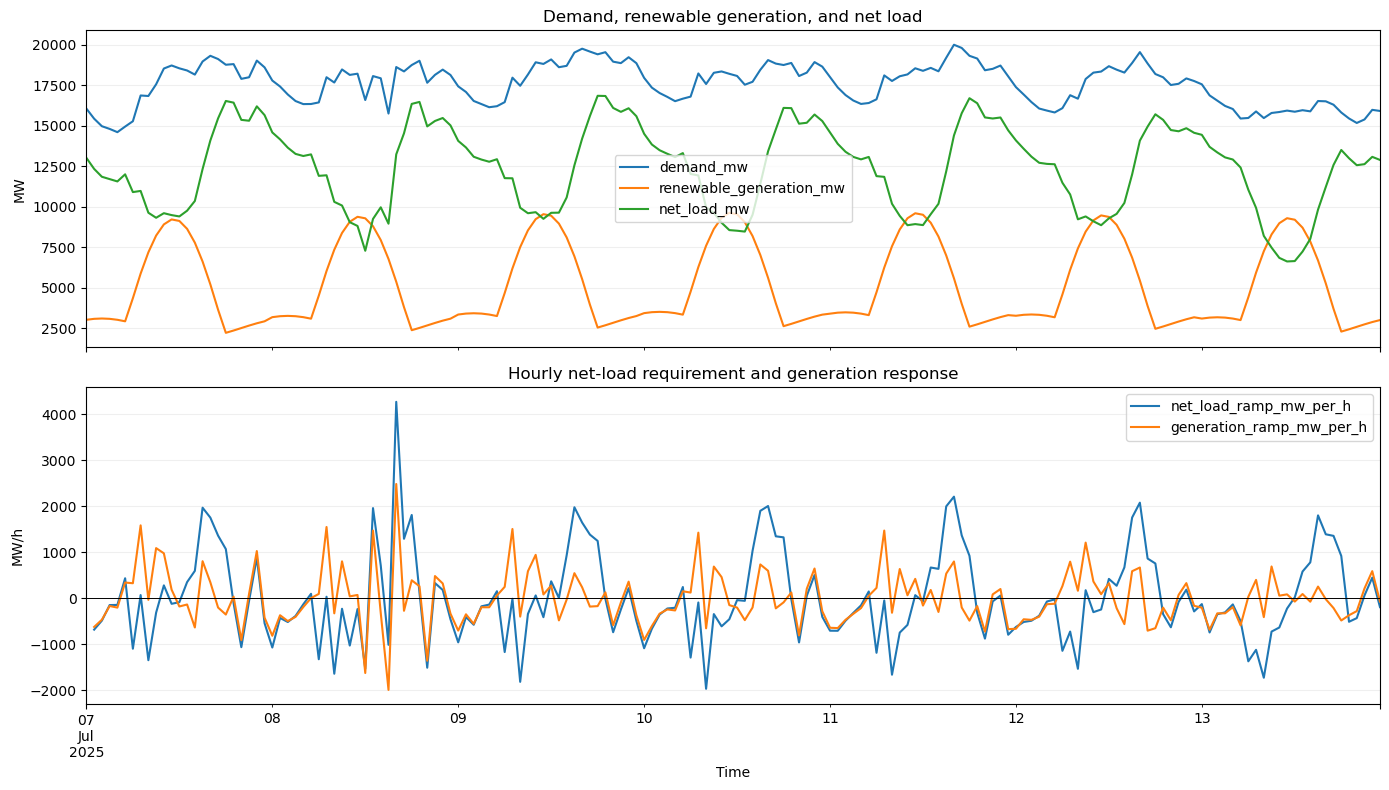

In [2]:
from pathlib import Path
import sys

from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'scripts').exists():
    ROOT = ROOT.parent
if not (ROOT / 'scripts').exists():
    raise FileNotFoundError('Run this notebook from the repository root or notebooks folder.')
sys.path.insert(0, str(ROOT / 'scripts'))

from results_analysis import analyze_run, export_analysis, load_analysis_run, load_observed_annual_generation, load_observed_capacity, load_observed_generation

run = load_analysis_run(ROOT / RESULT_PATH)
observed = load_observed_generation()
observed_annual = load_observed_annual_generation()
observed_capacity = load_observed_capacity()
analysis = analyze_run(run, observed, observed_annual, observed_capacity)
print(f'Loaded {run.run_type}: {run.snapshots[0]} to {run.snapshots[-1]} ({len(run.snapshots):,} hours)')

## Validation and system summary

In [3]:
display(analysis.tables['chronology_validation'])
display(analysis.tables['topology_validation'])
display(analysis.tables['system_metrics'].round(3))

,value,unit
metric,,
snapshot_count,168.0,snapshots
expected_contiguous_hours,168.0,hours
duplicate_snapshot_count,0.0,snapshots
non_hourly_step_count,0.0,steps
is_monotonic,1.0,boolean


,component_count,checkpoint_topology_mismatches
component,,
buses,9,0
generators,407,0
storage_units,4,0
stores,0,0
links,22,0
loads,9,0


,value,unit
metric,,
demand_energy,2950.557,GWh
peak_demand,19987.330,MW
renewable_generation,869.416,GWh
unserved_energy,0.000,MWh
hours_with_unserved_energy,0.000,hours
maximum_unserved_power,0.000,MW
maximum_upward_net_load_ramp,4273.450,MW/h
maximum_downward_net_load_ramp,-1966.066,MW/h
maximum_corridor_loading,100.000,%


## Generation, storage, commitment, and transmission

In [4]:
display(analysis.tables['generation_comparison'].round(2))
display(analysis.tables['storage_metrics'].round(2))
display(analysis.tables['store_metrics'].round(2))
display(analysis.tables['commitment_by_carrier'].round(2))
display(analysis.tables['corridor_metrics'].head(12).round(2))

,capacity_mw,modeled_generation_gwh,full_load_hours,observed_generation_gwh,difference_gwh,difference_pct,observed_implied_full_load_hours
carrier,,,,,,,
coal,15032.50,1483.86,98.71,1168.14,315.72,27.03,77.71
oil_gas,844.58,25.12,29.74,25.12,0.00,0.00,29.74
diesel,211.70,0.00,0.00,NaN,NaN,NaN,NaN
nuclear,2440.00,378.86,155.27,378.86,0.00,0.00,155.27
bio_power,1055.12,0.00,0.00,NaN,NaN,NaN,NaN
hydro,2203.20,197.76,89.76,177.16,20.60,11.63,80.41
solar,14121.46,406.47,28.78,321.02,85.45,26.62,22.73
wind,12299.49,462.95,37.64,970.23,-507.28,-52.28,78.88
unserved_energy,100000.00,0.00,0.00,NaN,NaN,NaN,NaN


,carrier,power_capacity_mw,energy_capacity_mwh,discharge_gwh,charge_gwh,minimum_soc_mwh,maximum_soc_mwh,equivalent_full_cycles
storage_unit,,,,,,,,
kadmparai_power_house__unit_01,hydro,100.0,600.0,2.83,3.54,-0.0,600.0,4.72
kadmparai_power_house__unit_02,hydro,100.0,600.0,2.76,3.45,-0.0,600.0,4.59
kadmparai_power_house__unit_03,hydro,100.0,600.0,2.73,3.41,-0.0,600.0,4.55
kadmparai_power_house__unit_04,hydro,100.0,600.0,2.77,3.46,-0.0,600.0,4.62


""


,units,capacity_mw,equivalent_online_hours,start_up_equivalents,shut_down_equivalents,fractional_status_hours,generation_gwh,start_up_equivalents_per_unit
carrier,,,,,,,,
bio_power,89,1055.12,0.0,0.0,0.0,0,0.00,0.00
coal,49,15032.50,6879.0,100.0,64.0,0,1483.86,2.04
diesel,14,211.70,0.0,0.0,0.0,0,0.00,0.00
oil_gas,14,844.58,663.0,99.0,85.0,0,25.12,7.07


,bus0,bus1,capacity_mw,maximum_absolute_flow_mw,maximum_loading_pct,p95_loading_pct,hours_at_or_above_99pct,net_energy_bus0_to_bus1_gwh
corridor,,,,,,,,
chennai_north__chennai_south,Chennai North,Chennai South,3500.0,3500.0,100.0,100.0,145,563.67
vellore__tirunelveli,Vellore,Tirunelveli,2500.0,2500.0,100.0,100.0,168,-420.00
coimbatore__tirunelveli,Coimbatore,Tirunelveli,1000.0,1000.0,100.0,100.0,168,-150.00
erode__tirunelveli,Erode,Tirunelveli,1000.0,1000.0,100.0,100.0,166,-154.85
erode__trichy,Erode,Trichy,8750.0,8750.0,100.0,100.0,16,-214.07
erode__coimbatore,Erode,Coimbatore,5000.0,5000.0,100.0,100.0,160,761.04
villupuram__tirunelveli,Villupuram,Tirunelveli,1000.0,1000.0,100.0,100.0,168,-160.00
villupuram__coimbatore,Villupuram,Coimbatore,1000.0,1000.0,100.0,100.0,168,154.00
chennai_north__vellore,Chennai North,Vellore,1000.0,1000.0,100.0,100.0,168,168.00


## Balancing areas and peak hour

In [5]:
display(analysis.tables['balancing_area_metrics'].round(3))
display(analysis.tables['installed_capacity_by_area'].round(3))
display(analysis.tables['renewable_generation_by_area'].round(3))
display(analysis.tables['peak_hour_by_area'].round(3))

,generation_gwh,storage_gwh,demand_gwh,net_import_gwh,balance_residual_gwh,peak_demand_mw
balancing_area,,,,,,
Chennai North,446.780,0.000,250.223,-196.556,0.0,1695.991
Chennai South,72.365,0.000,311.233,238.868,0.0,2100.175
Coimbatore,265.925,-2.772,454.787,191.635,-0.0,3090.824
Erode,205.136,0.000,381.544,176.408,-0.0,2571.724
Madurai,189.974,0.000,290.078,100.104,0.0,1969.410
Tirunelveli,1178.756,0.000,246.435,-932.321,0.0,1668.253
Trichy,84.297,0.000,355.878,271.582,0.0,2405.295
Vellore,13.698,0.000,356.673,342.975,-0.0,2413.220
Villupuram,496.399,0.000,303.705,-192.694,0.0,2072.437


capacity_mw
balancing_area carrier                     
Chennai North  bio_power              5.736
               coal                4677.500
               market_import        570.034
               oil_gas              120.000
               solar                340.296
...                                     ...
Villupuram     market_import        685.249
               small_hydro            7.500
               solar                557.778
               unserved_energy    10186.544
               wind                   1.717

[65 rows x 1 columns]

generation_gwh
balancing_area carrier                
Chennai North  solar             9.795
               wind              0.389
Chennai South  solar             6.403
               wind              0.288
Coimbatore     solar            26.954
               wind            131.352
Erode          solar            11.033
               wind              4.996
Madurai        solar           116.194
               wind             46.194
Tirunelveli    solar           175.733
               wind            243.069
Trichy         solar            39.468
               wind             29.220
Vellore        solar             4.831
               wind              7.377
Villupuram     solar            16.055
               wind              0.065

,timestamp,generation_mw,storage_mw,demand_mw,net_import_mw,balance_residual_mw
balancing_area,,,,,,
Chennai North,2025-07-11 16:00:00,3517.337,0.000,1695.991,-1821.346,0.0
Chennai South,2025-07-11 16:00:00,491.797,0.000,2100.175,1608.378,0.0
Coimbatore,2025-07-11 16:00:00,1647.573,193.039,3090.824,1250.213,0.0
Erode,2025-07-11 16:00:00,1436.746,0.000,2571.724,1134.979,0.0
Madurai,2025-07-11 16:00:00,1301.858,0.000,1969.410,667.552,-0.0
Tirunelveli,2025-07-11 16:00:00,6712.886,0.000,1668.253,-5044.634,-0.0
Trichy,2025-07-11 16:00:00,608.900,0.000,2405.295,1796.395,-0.0
Vellore,2025-07-11 16:00:00,76.164,0.000,2413.220,2337.056,-0.0
Villupuram,2025-07-11 16:00:00,4001.030,0.000,2072.437,-1928.593,0.0


## Export standardized artifacts

In [7]:
if SAVE_TABLES_AND_FIGURES:
    destination = export_analysis(
        run, analysis, None if OUTPUT_DIR is None else ROOT / OUTPUT_DIR
    )
    print(f'Analysis written to {destination}')

Analysis written to C:\Users\b076218\Documents\Filkassen\DEA_GE_github\PyPSA-TamilNadu\results\analysis
